[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TheBestProEver/100micron-sim/blob/main/notebooks/04_grain_on_a_wall.ipynb)

# 04 · A grain on the wall: what holds it, and what moves it

**The question.** Before DOLL-E's release mechanism acts, every grain rests on the glass wall of its tubule (on the
pad it settled on the tubule's bottom, the *aft face*). The rocket then pushes, spins, de-spins, falls back,
hangs from a parachute and hits the sea. **Which of these loads can pull a grain off the wall, slide it, roll it or
twist it?**

**After this notebook you can explain**
* why a 100 µm grain holds on to glass far harder than its own weight pulls on it, and where the formula
  $F_c = \tfrac32\pi w R$ comes from;
* the four ways a wall contact can give way (pull-off, sliding, rolling, twisting), the limit of each, and how each
  limit is derived;
* why **rolling**, whose limit is far below the pull-off limit, is what moves dust along the walls during the flight;
* why no flight load frees the dust, and what a release mechanism must therefore do.

It uses the readable core `dolle_core` (the same equations and numbers as the full simulator `dolle_sim`, checked
by `tests/test_dolle_core.py`) and the full simulator's flight timeline `dolle_sim.flight.FlightProfile`. The JKR
contact law itself is derived in notebook 01; here we use its results.

In [1]:
# Make the repository's packages (dolle_core, dolle_sim, and the optional extras) importable, in Colab or from a clone.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:   # in Colab: install the repository from GitHub (takes ~30 s)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/TheBestProEver/100micron-sim.git"], check=True)
else:                               # locally: the repository folder is this folder or the one above (notebooks/)
    repo = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "dolle_core").is_dir())
    sys.path.insert(0, str(repo))
    if (repo / "extras").is_dir():  # the optional v0.6 engine (extras/dolle_extras), used by the 3-D cells
        sys.path.insert(1, str(repo / "extras"))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import dolle_core as dc                       # the readable core: materials, JKR contact, wall limits
from dolle_core import nb_flight as nbf       # small helpers for tables and plots (no physics of their own)
from dolle_sim.flight import FlightProfile    # the full simulator's flight timeline (loads vs time)
G0 = dc.G0                                    # standard gravity, 9.80665 m/s^2: "1 g"

## 1. The set-up and the symbols

```
            pull-off: load away from the wall
                    ^
                .-''|''-.
              /     o-----> sideways load: sliding, rolling
             |   centre  |      radius R, density rho, mass m
              \         /
                '-.,.-'
      =========[==P==]=========  the wall; circular contact patch of radius a0 around the contact point P
```

| symbol | meaning | unit |
|---|---|---|
| $R$ | grain radius (sieve sizes such as "90–106 µm" are **diameters** $d = 2R$) | m |
| $\rho$ | grain density | kg/m³ |
| $m = \tfrac43\pi R^3\rho$ | grain mass | kg |
| $E^*$ | reduced (effective) Young's modulus of grain + wall, $1/E^* = (1-\nu_1^2)/E_1 + (1-\nu_2^2)/E_2$ (Hertz 1882; `dolle_core/pair.py`) | Pa |
| $\nu$ | Poisson ratio | – |
| $\gamma$ | surface energy of one free surface | J/m² |
| $w = 2\sqrt{\gamma_1\gamma_2}$ | work of adhesion: energy to separate 1 m² of contact (mixing rule ASSUMED, `pair.py`) | J/m² |
| $a$, $a_0$ | radius of the contact patch; $a_0$ its value at zero load | m |
| $F_c$ | pull-off force | N |
| $g_0 = 9.80665$ m/s² | standard gravity; "a load of $n$ g" means an acceleration of $n g_0$ | m/s² |

**Why express every limit as an acceleration in g.** All flight loads are inertial: in the frame of the tubule,
every grain feels a force $m\,a$ proportional to its own mass (exactly like gravity). The contact's limits are
forces or torques that do *not* scale with the mass. So for each limit we ask: which acceleration $a$ makes $m a$
reach it? That number can be compared directly with the flight's loads in g.

The grain we follow first: **silica, radius 50 µm (diameter 100 µm), on clean borosilicate glass**, the tubule glass
of the example payload.

In [3]:
R = 50e-6                                            # grain radius [m]
p = dc.make_pair("silica", R, "glass_borosilicate")  # r2 omitted: the second body is a flat wall (R* = R)
m = p.m1
print(f"work of adhesion   w  = {p.w:.4f} J/m^2   (2 sqrt(gamma_silica gamma_glass))")
print(f"reduced modulus    E* = {p.E_star / 1e9:.2f} GPa")
print(f"grain mass         m  = {m:.4e} kg,  weight m g0 = {m * G0 * 1e6:.4f} uN")

work of adhesion   w  = 0.0451 J/m^2   (2 sqrt(gamma_silica gamma_glass))
reduced modulus    E* = 30.10 GPa
grain mass         m  = 1.0472e-09 kg,  weight m g0 = 0.0103 uN


**Where $w$ comes from.** $w = 0.045$ J/m² is not a guess: the wall's effective surface energy in the material table
was chosen so that silica on clean glass gives the work of adhesion **measured for ~90 µm glass beads on clean
glass in room air**, 0.045 J/m² (Sansao et al. 2021, *Powder Technol.* 384, 267; `dolle_core/materials.py`). For
graphite on glass no measurement exists: its $w$ comes from the mixing rule (ASSUMED).

## 2. What holds the grain: JKR adhesion

From notebook 01 (Johnson, Kendall & Roberts 1971, *Proc. R. Soc. A* 324, 301; `dolle_core/jkr.py`), a sticky
elastic sphere on a flat has, for a contact patch of radius $a$, the normal force ($F>0$ pushes the grain away
from the wall, $F<0$ holds it on)

$$F(a) = \frac{4E^*a^3}{3R} - \sqrt{8\pi w E^* a^3}.$$

The first term is the Hertz (non-sticky) elastic push; the second is the pull of the adhesion around the edge of
the patch.

**Step 1: the grain at rest with no load.** No load means $F(a_0)=0$:

$$\frac{4E^*a_0^3}{3R} = \sqrt{8\pi wE^*a_0^3}
\;\Rightarrow\; \frac{16E^{*2}a_0^6}{9R^2} = 8\pi wE^*a_0^3
\;\Rightarrow\; a_0^3 = \frac{72\pi wR^2}{16E^*} = \frac{9\pi wR^2}{2E^*}.$$

So even with nothing pressing it, the grain sits on a patch of radius $a_0 = (9\pi wR^2/2E^*)^{1/3}$: the adhesion
squeezes the patch open until the elastic push balances it.

**Step 2: the pull-off force.** A flight load pulling the grain away is a *force* set by $m a$ (the contact cannot
change it): the grain sits at the patch radius where $F(a) = -m a$. Such an equilibrium exists only down to the
smallest value of $F(a)$; a larger pull has no equilibrium and the grain comes off. Set $dF/da = 0$:

$$\frac{dF}{da} = \frac{4E^*a^2}{R} - \frac32\sqrt{8\pi wE^*}\,a^{1/2} = 0
\;\Rightarrow\; a^{3/2} = \frac{3R\sqrt{8\pi wE^*}}{8E^*}
\;\Rightarrow\; a^3 = \frac{9R^2\,8\pi wE^*}{64E^{*2}} = \frac{9\pi wR^2}{8E^*} = \frac{a_0^3}{4}.$$

Put this $a$ back into $F$, using $a^{3/2} = 3R\sqrt{8\pi wE^*}/(8E^*)$:

$$F_{\min} = \frac{4E^*}{3R}\cdot\frac{9\pi wR^2}{8E^*} - \sqrt{8\pi wE^*}\cdot\frac{3R\sqrt{8\pi wE^*}}{8E^*}
= \frac32\pi wR - 3\pi wR = -\frac32\pi wR .$$

$$\boxed{F_c = \tfrac32\pi w R}\qquad\text{(the JKR pull-off force, reached at } a = a_0/4^{1/3}\text{)}$$

Remarkably, $F_c$ does not depend on the stiffness $E^*$ at all. The code checks both steps numerically:

In [4]:
a0 = (9 * math.pi * p.w * R**2 / (2 * p.E_star)) ** (1 / 3)          # step 1, by hand
F_c = 1.5 * math.pi * p.w * R                                         # step 2, by hand
a = np.linspace(0.05, 1.5, 20001) * a0                                # patch radii to scan
F = dc.force_of_radius(a, R, p.w, p.E_star)                           # JKR force at each radius [N]
print(f"a0  by hand {a0 * 1e9:.2f} nm,  dolle_core {dc.equilibrium_contact_radius(R, p.w, p.E_star) * 1e9:.2f} nm")
print(f"F_c by hand {F_c * 1e6:.4f} uN, dolle_core {dc.pull_off_force(R, p.w) * 1e6:.4f} uN")
print(f"scan: smallest F = {F.min() * 1e6:.4f} uN at a = {a[F.argmin()] / a0:.4f} a0 "
      f"(4^(-1/3) = {4 ** (-1 / 3):.4f})")
print(f"F_c / weight = {F_c / (m * G0):.1f}")

a0  by hand 375.40 nm,  dolle_core 375.40 nm
F_c by hand 10.6160 uN, dolle_core 10.6160 uN
scan: smallest F = -10.6160 uN at a = 0.6299 a0 (4^(-1/3) = 0.6300)
F_c / weight = 1033.7


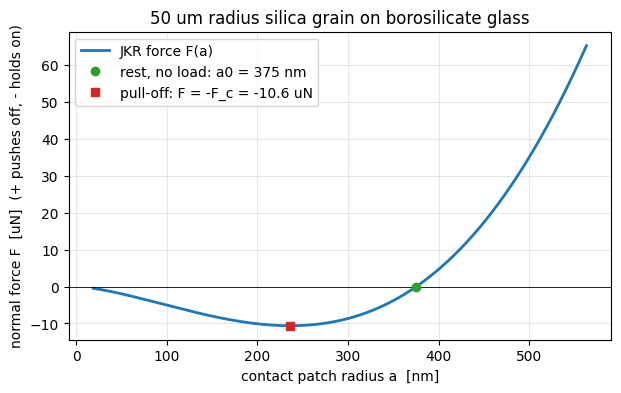

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(a * 1e9, F * 1e6, lw=2, label="JKR force F(a)")
ax.axhline(0, color="k", lw=0.6)
ax.plot(a0 * 1e9, 0, "o", color="C2", label=f"rest, no load: a0 = {a0 * 1e9:.0f} nm")
ax.plot(a0 / 4 ** (1 / 3) * 1e9, -F_c * 1e6, "s", color="C3", label=f"pull-off: F = -F_c = -{F_c * 1e6:.1f} uN")
ax.set_xlabel("contact patch radius a  [nm]")
ax.set_ylabel("normal force F  [uN]  (+ pushes off, - holds on)")
ax.set_title("50 um radius silica grain on borosilicate glass")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Why this happens.** The patch is tiny (about 0.4 µm across a 100 µm grain), but the adhesion acts all around its
edge, and the force it can hold scales with the grain's **size** $R$ (the pull is energy per area $w$ times a
length), while the weight scales with its **volume** $R^3$. For a 50 µm radius grain the hold wins by the factor
of about 1034 printed above: the weight (0.01 µN) is invisible on this plot.

Dividing by the mass gives the pull-off acceleration in closed form:

$$a_{\rm pull} = \frac{F_c}{m} = \frac{\tfrac32\pi wR}{\tfrac43\pi R^3\rho} = \frac{9\,w}{8\,\rho R^2}.$$

It falls as $1/R^2$: a grain ten times smaller holds a hundred times better (that is why fine dust clings to
everything and sand does not). Compare the hand formula with `dolle_core` and with the full simulator, whose
launch-load report (`dolle_sim/mission.py`) uses `dolle_sim.materials.pair_props`:

In [6]:
from dolle_sim import materials as sim_materials       # the full simulator's material table and pair properties
L = dc.wall_limits("silica", R, "glass_borosilicate")   # all four limits of this grain (dolle_core/wall.py)
sim = sim_materials.pair_props(sim_materials.get_material("silica"), R,
                               sim_materials.get_material("glass_borosilicate"), None)
rho = dc.get_material("silica").rho
print(f"a_pull = 9 w / (8 rho R^2) = {9 * p.w / (8 * rho * R**2) / G0:.2f} g   (hand formula, rho = {rho:.0f} kg/m^3)")
print(f"dolle_core wall_limits:      {L.pull_off_g:.2f} g")
print(f"dolle_sim pair_props F_c/mg: {sim.F_c / (m * G0):.2f} g   (relative difference {abs(sim.F_c / L.F_c - 1):.1e})")

a_pull = 9 w / (8 rho R^2) = 1033.74 g   (hand formula, rho = 2000 kg/m^3)
dolle_core wall_limits:      1033.74 g
dolle_sim pair_props F_c/mg: 1033.74 g   (relative difference 0.0e+00)


> **Why this choice: JKR pull-off, and not DMT or Maugis–Dugdale?**
> Three classic theories give the pull-off of a sticky sphere. **JKR** (soft, sticky, large spheres) gives
> $\tfrac32\pi wR$; **DMT** (Derjaguin, Muller & Toporov 1975, *J. Colloid Interface Sci.* 53, 314; stiff, small
> spheres) gives $2\pi wR$; **Maugis–Dugdale** (Maugis 1992, *J. Colloid Interface Sci.* 150, 243) spans the two.
> Which one applies is set by the Tabor parameter $\mu_T = (Rw^2/(E^{*2}z_0^3))^{1/3}$ (Tabor 1977; Johnson &
> Greenwood 1997, *J. Colloid Interface Sci.* 192, 326), with $z_0$ the range of the surface forces, 0.3 nm
> (ASSUMED; the simulator's notes use 0.2–0.4 nm): JKR above ~3–5, DMT well below 1.
> * For these 100 µm grains on glass (next cell), graphite comes out at 4–7, on the JKR side; silica at 1.2–2.4, in
>   the transition. The true pull-off therefore lies between $1$ and $4/3$ times the JKR value: **JKR is the lower
>   end**, so it is the cautious choice for the conclusion of this notebook ("the dust stays on").
> * The full simulator uses JKR for every contact (`dolle_sim/contact.py`, and the optional `extras/dolle_extras/dem.py`), and so does `dolle_core`.
> * Much larger than this factor 4/3 is the uncertainty of $w$ itself: the example payload spreads $w$ log-normally
>   with $\sigma = 0.6$ in $\ln w$ (about the scatter of measured adhesion forces on clean glass: Rush et al. 2018,
>   *J. Aerosol Sci.*, doi:10.1016/j.jaerosci.2018.06.002, as cited in PROVENANCE.md), and dry surfaces in vacuum may be several times stickier than in room air (Kimura et al. 2015,
>   *ApJ* 812, 67; Kreuzig et al. 2024, *A&A* 688, found no such rise for hydrophobic silica).

In [7]:
for grain in ("silica", "graphite"):
    q = dc.make_pair(grain, R, "glass_borosilicate")
    mu = [dc.tabor_parameter(R, q.w, q.E_star, z0) for z0 in (0.4e-9, 0.3e-9, 0.2e-9)]
    print(f"{grain:8s} on borosilicate (w = {q.w:.4f} J/m^2, E = {dc.get_material(grain).E / 1e9:.0f} GPa, "
          f"E* = {q.E_star / 1e9:.1f} GPa): Tabor parameter {mu[0]:.2f} - {mu[1]:.2f} - {mu[2]:.2f} "
          f"for z0 = 0.4, 0.3, 0.2 nm")
print(f"DMT / JKR pull-off = 2 pi w R / (1.5 pi w R) = {2 / 1.5:.3f}")

silica   on borosilicate (w = 0.0451 J/m^2, E = 54 GPa, E* = 30.1 GPa): Tabor parameter 1.21 - 1.61 - 2.41 for z0 = 0.4, 0.3, 0.2 nm
graphite on borosilicate (w = 0.0780 J/m^2, E = 10 GPa, E* = 9.5 GPa): Tabor parameter 3.74 - 4.99 - 7.49 for z0 = 0.4, 0.3, 0.2 nm
DMT / JKR pull-off = 2 pi w R / (1.5 pi w R) = 1.333


**Why this happens.** The Tabor parameter compares the height of the "neck" the adhesion pulls up around the edge of
the contact with the range of the surface forces. Soft, sticky, large grains pull up a tall neck (JKR); stiff ones
hardly deform and feel the surface forces only outside the contact (DMT). Graphite is both softer and, on glass,
stickier than silica, so it sits further toward JKR.

## 3. Sliding

A sideways load (along the wall) shears the contact patch. The patch first resists like a spring, with the elastic
shear stiffness of a circular contact (Mindlin 1949, *J. Appl. Mech.* 16, 259; in the form of Wada et al. 2007,
*ApJ* 661, 320, eqs. 12–13,
which the optional 3-D model uses, `extras/dolle_extras/dem.py`):

$$k_s = 8\,G^*a_0,\qquad \frac1{G^*} = \frac{2-\nu_1}{G_1}+\frac{2-\nu_2}{G_2},\qquad G = \frac{E}{2(1+\nu)}\ \text{(shear modulus, Pa)}.$$

It slips when the spring force reaches the friction limit, which for a sticky contact is written

$$F_{s,\max} = \mu\,\lvert F_{ne} + 2F_c\rvert$$

(Thornton & Yin 1991, *Powder Technol.* 65, 153; Marshall 2009, *J. Comput. Phys.* 228, 1541, eq. 43; the same form
as LAMMPS, an open-source molecular-dynamics code whose granular package the simulator matches term by term). $\mu$ is the friction coefficient and $F_{ne}$ the elastic normal
force, zero for a grain resting with no load. The adhesion acts like an extra pressing load of $2F_c$ that friction
has to overcome.

**The limit as an acceleration.** At rest the spring carries the whole sideways load, $k_s x = m a_t$. It slips when
$m a_t = 2\mu F_c$:

$$a_{\rm slide} = \frac{2\mu F_c}{m} = 2\mu\,a_{\rm pull}.$$

With $\mu = 0.4$ (silica on glass, measured: Meyer, Fuchs, Staedler & Jiang 2014, *Friction* 2, 255;
`dolle_core/materials.py` FRICTION) that is $0.8\,a_{\rm pull}$:

In [8]:
x_slip = 2 * L.mu * L.F_c / L.k_slide          # spring stretch at the moment it slips [m]
print(f"mu = {L.mu},  k_s = 8 G* a0 = {L.k_slide:.3e} N/m")
print(f"sliding limit 2 mu F_c / m = {2 * L.mu * L.F_c / (m * G0):.1f} g   (dolle_core: {L.slide_g:.1f} g)")
print(f"the patch shears by only {x_slip * 1e9:.2f} nm before it slips")

mu = 0.4,  k_s = 8 G* a0 = 2.031e+04 N/m
sliding limit 2 mu F_c / m = 827.0 g   (dolle_core: 827.0 g)
the patch shears by only 0.42 nm before it slips


**Why this happens.** Friction is proportional to how hard the surfaces are pressed together, and for a 100 µm grain
the adhesion presses about a thousand times harder than its weight. So sliding, like pull-off, needs hundreds of g.

> **Why this choice: friction "with the adhesion offset".** A plain $\mu F_{ne}$ would give zero friction for a grain
> resting with no load, which contradicts the measured friction of adhesive microspheres (Heim et al. 1999, *PRL*
> 83, 3328). The $|F_{ne}+2F_c|$ form is the one in the published granular codes (Marshall 2009; LAMMPS), and the full
> simulator reproduces LAMMPS with it term by term (CHECKS.md, `extras/tools/lammps_contact_check.py`). The coefficients are
> 0.4 for silica on glass (Meyer et al. 2014) and 0.6 for silica on silica (Liu et al. 2017, *Nat. Commun.* 8, 14029,
> its uncoated-silica reference, as `extras/dolle_extras/engine.py` (MU_DEFAULT) cites it; not re-checked here). Graphite's 0.5 is
> graphite in dry gas or vacuum (Buckley 1971, 1973), and graphite on glass is ASSUMED to be the same. A carbon's
> friction depends strongly on its surface: Liu et al. measured about 0.003 for graphene-coated contacts, so for a
> carbon grain $\mu$ is uncertain by more than 100×. (For pull-off and rolling, the limits that matter in this
> notebook, $\mu$ does not enter.)

## 4. Rolling: the weak limit

A grain can also give way by **rolling**. As it rolls, the contact patch is pushed forward: contact is made at the
front edge and broken at the back. Breaking a sticky contact costs more energy than making it returns (the adhesion
*hysteresis*, the same effect that makes slow grains stick, notebook 01), so rolling costs energy and the contact
resists it with a torque (Dominik & Tielens 1995, *Phil. Mag. A* 72, 783): the patch is displaced relative to the
point below the centre, the adhesive pull at its trailing edge is no longer balanced by the leading edge, and that
lopsided pressure turns the grain back. The simulator models this torque as a spring with a limit
(the optional `extras/dolle_extras/dem.py`, written in the form of LAMMPS "rolling sds"; the default v0.5 engine holds wall
grains until they are pulled off and does not model rolling):

* rolling spring $k_r = 4F_c/R$ (Wada et al. 2007 eq. 22, the Dominik & Tielens rolling resistance), acting on the
  rolling displacement $\xi$ (how far the patch has been rolled), giving a torque $M = k_r\,\xi\,R = 4F_c\,\xi$;
* it holds up to the critical rolling displacement $\xi_{\rm crit} = h\,a_0/12$ (Krijt, Dominik & Tielens 2014,
  *J. Phys. D* 47, 175302, eq. 16), where $h$ is a dimensionless measure of the adhesion hysteresis, **0.5
  (ASSUMED)**. The largest torque is written, like friction, with the normal bracket:
  $M_r = \frac{2\xi_{\rm crit}}{R}\,\lvert F_{ne} + 2F_c\rvert\,R$ (`dem.py make_params`), which at zero load
  ($F_{ne} = 0$) is $M_r = 4F_c\,\xi_{\rm crit}$ = $k_r\xi_{\rm crit}R$.

**The limit as an acceleration: torque balance about the contact point $P$.** The sideways load $m a_t$ acts at the
centre, a height $R$ above $P$, so its torque about $P$ is $m a_t R$. The normal force and the friction force both act
*at* $P$, so their torque about $P$ is zero. At rest the rolling torque must balance:

$$M = m\,a_t\,R .$$

The grain starts to roll when $M$ reaches $M_r$:

$$a_{\rm roll} = \frac{4F_c\,\xi_{\rm crit}}{mR} = \frac{4F_c}{mR}\cdot\frac{h a_0}{12} = \frac{h\,a_0}{3R}\cdot\frac{F_c}{m}
\qquad\Rightarrow\qquad \boxed{\frac{a_{\rm roll}}{a_{\rm pull}} = \frac{h\,a_0}{3R}}.$$

The patch is about 1/130 of the grain's radius, so rolling needs about a thousand times less than pull-off:

In [9]:
xi_crit = 0.5 * L.a0 / 12                                # h = 0.5
a_roll = 4 * L.F_c * xi_crit / (m * R)                   # [m/s^2]
print(f"a0 / R = {L.a0 / R:.4f}   xi_crit = h a0 / 12 = {xi_crit * 1e9:.2f} nm   M_r = {4 * L.F_c * xi_crit:.3e} N m")
print(f"rolling limit 4 F_c xi_crit / (m R) = {a_roll / G0:.4f} g   (dolle_core: {L.roll_g:.4f} g)")
print(f"a_roll / a_pull = {L.roll_g / L.pull_off_g:.3e}   (h a0 / (3 R) = {0.5 * L.a0 / (3 * R):.3e})")

a0 / R = 0.0075   xi_crit = h a0 / 12 = 15.64 nm   M_r = 6.642e-13 N m
rolling limit 4 F_c xi_crit / (m R) = 1.2935 g   (dolle_core: 1.2935 g)
a_roll / a_pull = 1.251e-03   (h a0 / (3 R) = 1.251e-03)


**Why this happens.** The load acts at the centre with the whole radius $R$ as its lever, while the contact resists
rolling only over the tiny patch (its "lever" is $\xi_{\rm crit} \approx a_0/24$, about 16 nm here). A load of about
1.3 g sideways is enough to roll a 100 µm silica grain on clean glass, far less than the sideways loads of the
flight: the spin's 9.6 g at the far corner of tubule T1 and the guide's ±10 g lateral envelope (section 6).

> **Why this choice, and how uncertain is it?** The spring-with-a-limit form is the standard one for adhesive grains
> (Dominik & Tielens 1995; Wada et al. 2007; Krijt et al. 2014) and is what LAMMPS implements; the simulator matches
> LAMMPS on a rolling ramp (CHECKS.md, LAMMPS set-up B_rolling_ramp). The weak point is **h**: 0.5 is Krijt et al.'s fit
> to rolling of ~1 µm silica spheres (Heim et al. 1999); the only measurement at DOLL-E's sizes (70 µm glass beads in
> a wind tunnel, Ibrahim, Dunn & Brach 2003, *J. Aerosol Sci.* 34, 765) gives $h$ = 0.05–0.6, and the published models
> span about 50× (PROVENANCE.md, "Rolling"). No measurement exists for graphite. Because $a_{\rm roll}\propto h$, the
> next cell spans the measured range:

In [10]:
for h in (0.05, 0.5, 0.6):
    print(f"h = {h:4.2f}: silica (R = 50 um) on borosilicate rolls at "
          f"{dc.wall_limits('silica', R, 'glass_borosilicate', h=h).roll_g:.3f} g")

h = 0.05: silica (R = 50 um) on borosilicate rolls at 0.129 g
h = 0.50: silica (R = 50 um) on borosilicate rolls at 1.294 g
h = 0.60: silica (R = 50 um) on borosilicate rolls at 1.552 g


**Why this happens.** The rolling limit is simply proportional to $h$, so the measured range moves it more than
tenfold. Even its top end is a small sideways load; section 6 compares it with the flight's.

**Past the limit: rolling without slipping.** Once $M = M_r$ the torque stays at that value and the grain rolls.
Take the grain's speed $v$ (along the load), its spin $\omega$, and the friction force $T$ at $P$ (pointing
back). Newton's law for the centre, the torque balance about the centre (moment of inertia $I = \tfrac25 mR^2$ for
a solid sphere) and rolling without slipping ($v = \omega R$) give

$$m\dot v = m a_t - T,\qquad I\dot\omega = TR - M_r,\qquad \dot\omega = \dot v/R$$

$$\Rightarrow\; T = \frac{I\dot v}{R^2} + \frac{M_r}{R}
\;\Rightarrow\; \Big(m + \frac{I}{R^2}\Big)\dot v = m a_t - \frac{M_r}{R} = m\,(a_t - a_{\rm roll})
\;\Rightarrow\; \boxed{\dot v = \frac{a_t - a_{\rm roll}}{1.4}}.$$

The friction needed, $T = m a_{\rm roll} + 0.4\,m\dot v$, is a few g times $m$, far below the sliding limit of hundreds
of g: the grain rolls and does not slip (`dolle_core.rolling_acceleration`).

**Checked against the full simulator's 3-D contact model.** The next cell runs `extras/dolle_extras/dem.py` (DEM, the
discrete element method: every grain a sphere with six degrees of freedom moved by Newton's laws, with normal,
sliding, rolling and twisting springs at its contacts, ~10 ns steps) with the set-up of
its own check `dolle_extras.verify_full.check_rolling_on_wall`: the 50 µm grain, pressed on the wall by 1 g, under a sideways load
ramped from 0 to 3× its rolling limit in 2 ms. It takes a few seconds (it needs numba and the `extras/` folder; the first run
compiles the 3-D engine, about a minute; without them the next two cells print nothing). The formula it is compared with is the "rigid-plastic" one: the grain does not move
at all below the limit, and beyond it the torque stays exactly at $M_r$ (no springs, like a rigid-plastic material).

In [11]:
run = nbf.dem_rolling_ramp()          # 200,000 steps of the full 3-D contact model
if run is not None:
    v_formula = nbf.rigid_plastic_rolling_speed(run["t"], run["ramp"], run["a_roll_sim"])
    a_pressed = dc.wall_limits("silica", R, "glass_borosilicate", press_g=1.0).roll_g * G0
    print(f"rolling limit used by the check {run['a_roll_sim'] / G0:.4f} g (zero load); with the 1 g pressing "
          f"{a_pressed / G0:.4f} g")
    print(f"final speed: 3-D model {run['v'][-1] * 1e3:.3f} mm/s, formula {v_formula[-1] * 1e3:.3f} mm/s "
          f"(difference {run['v'][-1] / v_formula[-1] - 1:.1e}); with the pressed limit "
          f"{nbf.rigid_plastic_rolling_speed(run['t'][-1], run['ramp'], a_pressed) * 1e3:.3f} mm/s")
    print(f"slip |v - omega R| / v at the end: {abs(run['v'][-1] - run['omega_R'][-1]) / run['v'][-1]:.1e}")

rolling limit used by the check 1.2935 g (zero load); with the 1 g pressing 1.2942 g
final speed: 3-D model 12.120 mm/s, formula 12.081 mm/s (difference 3.2e-03); with the pressed limit 12.075 mm/s
slip |v - omega R| / v at the end: 2.3e-08


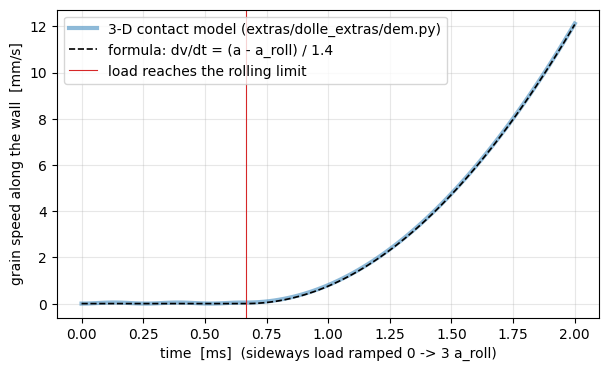

In [12]:
if run is not None:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(run["t"] * 1e3, run["v"] * 1e3, lw=3, alpha=0.5, label="3-D contact model (extras/dolle_extras/dem.py)")
    ax.plot(run["t"] * 1e3, v_formula * 1e3, "k--", lw=1.2, label="formula: dv/dt = (a - a_roll) / 1.4")
    ax.axvline(run["a_roll_sim"] / run["ramp"] * 1e3, color="C3", lw=0.8, label="load reaches the rolling limit")
    ax.set_xlabel("time  [ms]  (sideways load ramped 0 -> 3 a_roll)")
    ax.set_ylabel("grain speed along the wall  [mm/s]")
    ax.legend(); ax.grid(alpha=0.3)
    plt.show()

**Why this happens.** Below the limit the grain stays put (it only leans on its springs by nanometres); at the limit
it starts to roll and then accelerates at $(a_t - a_{\rm roll})/1.4$, as derived, without slipping. The 1 g pressing
raises the limit by only 0.05 % (in $M_r$ the bracket $|F_{ne} + 2F_c|$ grows by $m g_0$ out of
$2F_c \approx 2000\,m g_0$), which alone would make the 3-D grain slightly SLOWER than the zero-load formula; it is
in fact 3e-3 faster. That difference comes from the springs the formula leaves out (their elastic deflection before
the limit and their damping); it has not been split into its parts here, and it is within the 1e-2 the simulator's
check accepts (CHECKS.md, check 3).

## 5. Twisting

The last way is to twist the grain about the wall's normal. The twisting spring is $k_{tw} = \tfrac{16}{3}G_{tw}a_0^3$
with the twisting modulus $1/G_{tw} = 1/G_1 + 1/G_2$ (not the sliding modulus $G^*$ of section 3). It holds up to the
critical twist angle $\varphi_{\rm crit} = 1/(16\pi)$ (Wada et al. 2007), so the limit torque at zero load is
$M_{tw} = k_{tw}\varphi_{\rm crit} = \tfrac{16}{3}G_{tw}a_0^3\cdot\tfrac{1}{16\pi} = G_{tw}a_0^3/(3\pi)$ (Wada et al. 2007, eqs. 26
and 37); under a load the simulator scales it by $|F_{ne} + 2F_c|/(2F_c)$, like the rolling limit
(`dolle_core/wall.py`, `extras/dolle_extras/dem.py`).

A uniform acceleration cannot twist the grain: the load acts at the centre, on the wall's normal through $P$, so its
torque about that normal is zero. Only an **angular acceleration $\alpha$ of the wall about its normal** can: to turn
the grain with the wall the contact must supply the torque $I\alpha$, so the grain twists loose when
$\alpha > M_{tw}/I$. For the aft face the normal *is* the rocket's spin axis, so the spin-up and the de-spin are
exactly such angular accelerations. The fastest is the yo-yo de-spin (two weights on cables unwind from the
spinning payload and are released, carrying the spin away), at T+54 s ("T+$t$" means $t$ seconds after lift-off;
`FlightProfile`, printed below):

In [13]:
prof = FlightProfile()                               # the full simulator's flight timeline, default (nominal) values
alpha_despin = abs(prof.spin_rate_dot(prof.despin_s + 0.5 * prof.despin_duration_s))   # [rad/s^2]
print(f"de-spin: {prof.spin_burnout_hz} Hz -> {prof.residual_spin_hz:.4f} Hz (1 rpm) in {prof.despin_duration_s} s "
      f"at T+{prof.despin_s:.0f} s")
print(f"twisting limit torque G a0^3 / (3 pi) = {L.twist_torque:.3e} N m,  I = 0.4 m R^2 = {0.4 * m * R**2:.2e} kg m^2")
print(f"angular acceleration that twists the grain loose: {L.twist_angular_acc:.3e} rad/s^2")
print(f"de-spin angular acceleration: {alpha_despin:.2f} rad/s^2  ->  margin {L.twist_angular_acc / alpha_despin:.1e}")

de-spin: 4.8 Hz -> 0.0167 Hz (1 rpm) in 0.9 s at T+54 s
twisting limit torque G a0^3 / (3 pi) = 6.893e-11 N m,  I = 0.4 m R^2 = 1.05e-18 kg m^2
angular acceleration that twists the grain loose: 6.583e+07 rad/s^2
de-spin angular acceleration: 33.39 rad/s^2  ->  margin 2.0e+06


**Why this happens.** The grain's moment of inertia is minute ($I = \tfrac25 mR^2 \approx 10^{-18}$ kg m²), so even
a violent de-spin needs a torque millions of times below what the patch holds. Twisting never matters for wall dust
in this flight.

## 6. The flight's loads, as the dust on the aft face feels them

The loads come from the full simulator's `dolle_sim.flight.FlightProfile` with its default (nominal) parameters,
whose sources are listed in `dolle_sim/flight.py` and in notebook 05. In the tubule's frame a free grain appears to
accelerate at $-\mathbf f$, minus the payload's specific force $\mathbf f$ (what an accelerometer reads). The table
gives, for each phase, the largest load **pulling dust off** the aft face, **pressing** it on, and acting **along**
it (the spin's centrifugal load $\Omega^2 r$, the Euler load $-\dot{\boldsymbol\Omega}\times\mathbf r$ while the spin rate $\Omega$
changes, plus any sideways part). The spin load grows with the distance from the
spin axis, so it is taken at the corner of example tubule T1 farthest from the axis (as the simulator's launch-load
report does, `dolle_sim/mission.py`).

In [14]:
tubules, source = nbf.example_tubules()      # the four example tubules of configs/mission_quarter_deck.json
T1 = tubules[0]
r_far = nbf.far_corner(T1)                   # [m] in the deck plane, from the spin axis
print(f"tubules from: {source}\nT1 = {T1['name']}, far corner {np.hypot(*r_far) * 100:.2f} cm from the spin axis\n")
loads = nbf.aft_face_loads(prof, r_far)
nbf.print_table(loads, [("phase", "phase", ""), ("t0", "from T+ [s]", ".1f"), ("t1", "to T+ [s]", ".1f"),
                        ("pull_off_aft_g", "pull off [g]", ".3g"), ("press_on_aft_g", "press on [g]", ".3g"),
                        ("along_face_g", "along [g]", ".3g"), ("spin_hz_max", "spin [Hz]", ".3g")])
print(f"\nnot in the table: the guide's lateral ascent envelope, +/- {prof.lateral_g:.0f} g along the face (burns)")

tubules from: configs/mission_quarter_deck.json
T1 = T1_silica_90-106um_bare, far corner 10.31 cm from the spin axis



phase                          from T+ [s]  to T+ [s]  pull off [g]  press on [g]  along [g]  spin [Hz]
-----------------------------  -----------  ---------  ------------  ------------  ---------  ---------
first-stage burn               0.0          5.2        0             25            0.304      0.856    
coast between burns            5.2          17.4       3             0             3.41       2.87     
second-stage burn              17.4         29.1       0             25            9.54       4.8      
coast in the upper atmosphere  29.1         54.0       2.95          0             9.56       4.8      
de-spin                        54.0         54.9       0.00874       0             9.52       4.79     
coast to ~100 km               54.9         88.0       0.00727       0             0.000115   0.0167   
microgravity (above ~100 km)   88.0         313.0      0.0001        0.000244      0.000115   0.0167   
re-entry                       313.0        460.0      0        

**Reading the table.**
* **Burns** (25 g, the design envelope of the payload user guide): the thrust *presses* the dust onto the aft face.
* **Coasts**: air drag decelerates the rocket, so the dust is *pulled off* the aft face, by about 3 g (a derived
  estimate in `flight.py`).
* **Spin**: the rocket spins up to 4.8 Hz by the end of the second burn. At T1's far corner the centrifugal load
  $\Omega^2 r$ reaches about 9.6 g **along** the aft face, until the de-spin at T+54 s.
* **Re-entry**: the payload falls side-on, and the 7.9 g deceleration peak acts **along** the aft face.
* **Parachute (5 g) and splashdown (31 g)**: hanging nose down, these pull the dust **off** the aft face.
* **Microgravity window**: about $10^{-4}$ g (ASSUMED residual) and the 1 rpm residual spin.

## 7. Loads against limits for the example dust (45–106 µm)

The example payload has silica and graphite of 90–106 µm on bare borosilicate (T1, T2) and of 45–53 µm on silanised
(water-repellent) glass (T3, T4). The plot shows the pull-off (solid) and rolling (dashed) limits across 45–106 µm
for each grain on each glass, with the flight's loads as grey lines. Sliding is $2\mu$ times pull-off (0.8× for
silica, 1.0× for graphite, whose $\mu = 0.5$), so it is not drawn.

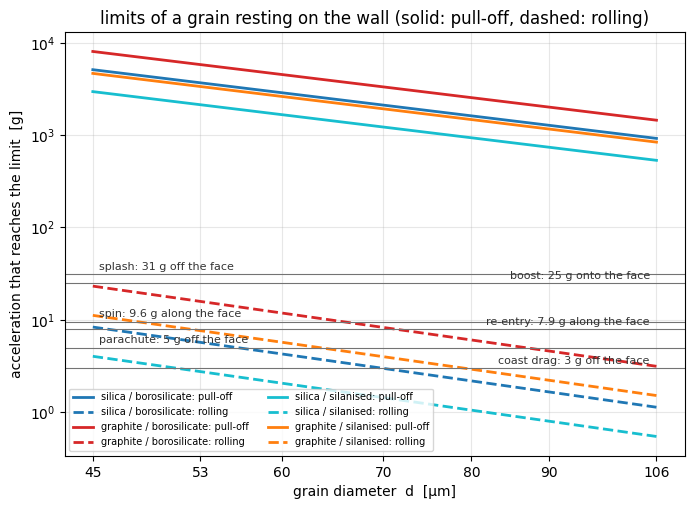

In [15]:
cases = [("silica / borosilicate", "silica", "glass_borosilicate", "C0"),
         ("graphite / borosilicate", "graphite", "glass_borosilicate", "C3"),
         ("silica / silanised", "silica", "glass_silanized", "C9"),
         ("graphite / silanised", "graphite", "glass_silanized", "C1")]
by = {row["phase"]: row for row in loads}
flight_lines = [("splash: 31 g off the face", by["splashdown"]["pull_off_aft_g"]),
                ("boost: 25 g onto the face", 25.0),
                ("spin: 9.6 g along the face", by["coast in the upper atmosphere"]["along_face_g"]),
                ("re-entry: 7.9 g along the face", by["re-entry"]["along_face_g"]),
                ("parachute: 5 g off the face", by["parachute opening"]["pull_off_aft_g"]),
                ("coast drag: 3 g off the face", by["coast between burns"]["pull_off_aft_g"])]
ax = nbf.plot_limits_vs_diameter(cases, flight_lines)
ax.set_title("limits of a grain resting on the wall (solid: pull-off, dashed: rolling)")
plt.show()

In [16]:
d = np.array([45e-6, 106e-6])
for label, grain, wall, _ in cases:
    lim = nbf.limits_vs_diameter(grain, wall, d)
    print(f"{label:24s} w = {dc.make_pair(grain, 1e-5, wall).w:.4f} J/m^2; d = 45 / 106 um: pull-off {lim['pull_off_g'][0]:6.0f} / {lim['pull_off_g'][1]:5.0f} g, "
          f"rolling {lim['roll_g'][0]:5.2f} / {lim['roll_g'][1]:4.2f} g")
lim = nbf.limits_vs_diameter("silica", "glass_borosilicate", d)
print(f"slopes (log-log): pull-off {np.log(lim['pull_off_g'][1] / lim['pull_off_g'][0]) / np.log(d[1] / d[0]):.3f}, "
      f"rolling {np.log(lim['roll_g'][1] / lim['roll_g'][0]) / np.log(d[1] / d[0]):.3f}")

silica / borosilicate    w = 0.0451 J/m^2; d = 45 / 106 um: pull-off   5105 /   920 g, rolling  8.34 / 1.13 g
graphite / borosilicate  w = 0.0780 J/m^2; d = 45 / 106 um: pull-off   8038 /  1449 g, rolling 23.13 / 3.13 g
silica / silanised       w = 0.0261 J/m^2; d = 45 / 106 um: pull-off   2955 /   532 g, rolling  4.02 / 0.54 g
graphite / silanised     w = 0.0452 J/m^2; d = 45 / 106 um: pull-off   4652 /   838 g, rolling 11.16 / 1.51 g
slopes (log-log): pull-off -2.000, rolling -2.333


**Why this happens.**
* **The size dependence.** $a_{\rm pull} = 9w/(8\rho R^2) \propto d^{-2}$. For rolling, $a_{\rm roll} = h a_0 F_c/(3mR)$
  with $F_c\propto wR$, $a_0 \propto (wR^2/E^*)^{1/3}$ and $m \propto \rho R^3$, so
  $a_{\rm roll} \propto w^{4/3}E^{*-1/3}\rho^{-1}R^{-7/3}$: slopes −2 and −7/3, as printed.
* **Graphite holds harder than silica** although it is denser: its $w$ on glass is larger (0.078 J/m² from the
  mixing rule, against the 0.045 J/m² measured for glass beads) and it is softer ($E$ = 10 vs 54 GPa), so its patch
  $a_0$ is larger, which raises the rolling limit further (pull-off does not depend on $E$).
* **Silanised glass holds less** ($w$ = 0.026 J/m² for silica: the value measured for silanised beads on silanised
  glass, Sansao et al. 2021; Zafar et al. 2014; applying it to untreated grains on silanised glass is ASSUMED, as that
  pair has never been measured), but the smaller grains of T3/T4 more than make up for it.
* **The adhesion scatter.** The example payload draws each grain's $w$ from a log-normal distribution whose median
  is the nominal $w$, with $\sigma = 0.6$ in $\ln w$. 1.2816 is the 10th-percentile point of a standard normal
  distribution, so one grain in ten has $w$ below $e^{-1.2816\times0.6}$ times the nominal value. Pull-off scales as $w$
  and rolling as $w^{4/3}$:

In [17]:
f10 = math.exp(-1.2816 * 0.6)          # 10th percentile of a log-normal factor with sigma 0.6
weak = dc.wall_limits("silica", 106e-6 / 2, "glass_borosilicate", f_adh=f10)   # T1's largest grain, weak adhesion
print(f"10th-percentile adhesion factor {f10:.3f}: pull-off x {f10:.3f}, rolling x {f10 ** (4 / 3):.3f}")
print(f"T1's weakest grains (d = 106 um, w x {f10:.3f}): pull-off {weak.pull_off_g:.0f} g, rolling {weak.roll_g:.2f} g")

10th-percentile adhesion factor 0.463: pull-off x 0.463, rolling x 0.359
T1's weakest grains (d = 106 um, w x 0.463): pull-off 426 g, rolling 0.41 g


**Why this happens.** A weaker contact both pulls less ($F_c\propto w$) and has a smaller patch ($a_0\propto w^{1/3}$),
so rolling, which needs both, falls faster with $w$ than pull-off does.

## 8. What this means for the flight

**(a) Nothing comes off.** The largest load pulling dust off the wall in the whole flight is the 31 g splashdown;
the weakest grains (106 µm silica on bare glass, with one-in-ten weak adhesion) need over 400 g. The boost's 25 g
presses the dust *on*. This is the conclusion of the simulator's launch-load report too (docs/MISSION_RUNS.md, "Mission runs").

**(b) Rolling is what moves wall dust.** The example dust's rolling limits are about 1–11 g, and three sideways
loads exceed most of them: the spin (up to 9.6 g), the guide's lateral ascent envelope (±10 g) and the side-on
re-entry (7.9 g). Each rolls the grains whose limit it exceeds along the face. With the spin
rising linearly through the boost (ASSUMED shape), the rolling limit is passed partway through the coast between
the burns (T1) or in the second burn (T2–T4); the grains then roll to the outer side of the face and pile up against
the side wall. The estimate below takes the load at the far corner throughout (the fastest case), a roll of one
tubule width (12.7 mm, ASSUMED path) from rest, and ignores Coriolis:

In [18]:
for tb in tubules:
    roll_g = dc.wall_limits(tb["dust"], tb["d_max"] / 2, tb["wall"]).roll_g          # the largest grain rolls first
    t_on, t_wall, v_wall = nbf.roll_to_wall(prof, nbf.far_corner(tb), roll_g, 0.5 * 0.0254)
    print(f"{tb['name']:30s} rolling limit {roll_g:5.2f} g: starts rolling at T+{t_on:5.1f} s, "
          f"reaches the side wall at T+{t_wall:5.2f} s at {v_wall * 1e3:4.0f} mm/s")

T1_silica_90-106um_bare        rolling limit  1.13 g: starts rolling at T+ 10.0 s, reaches the side wall at T+10.36 s at  105 mm/s


T2_graphite_90-106um_bare      rolling limit  3.13 g: starts rolling at T+ 18.9 s, reaches the side wall at T+19.22 s at  119 mm/s


T3_silica_45-53um_silanized    rolling limit  2.74 g: starts rolling at T+ 17.7 s, reaches the side wall at T+18.02 s at  117 mm/s


T4_graphite_45-53um_silanized  rolling limit  7.62 g: starts rolling at T+ 26.0 s, reaches the side wall at T+26.23 s at  144 mm/s


**Why this happens.** The centrifugal load grows as the square of the spin rate, so it creeps past the small rolling
limit early in the flight, and once a grain rolls nothing but the same small rolling torque resists it. The dust
does not leave the wall: it rolls **along** it and collects at the outer wall, so where the dust sits when the
experiment starts is set by the spin, not by where it was loaded. The optional v0.6 full-contact engine (`extras/`) models this rolling;
the default v0.5 engine holds wall grains in place and cannot (docs/MISSION_RUNS.md, design point 5).

**(c) What a release mechanism must do.** Rolling cannot free a grain (it stays in contact), so a release must exceed
the **pull-off** limit: about 400 to 5,000 g for the example dust. A quasi-steady shake cannot do that. A sharp kick
can, but a grain leaves a shaken wall at about the wall's own speed (the simulator's ASSUMPTION; it ignores the
elastic energy stored in the contact, PROVENANCE.md "Release from the wall"), and for a sinusoidal motion of acceleration
amplitude $a$ and frequency $f$ ($x = A\sin 2\pi ft$) the peak speed is $v = a/(2\pi f)$ (because $a = (2\pi f)^2A$
and $v = 2\pi f A$). The settings of the simulator's scenarios, and the frequency a 1,000 g release would need to
leave at 1 cm/s:

In [19]:
v_stick = dc.sticking_threshold(dc.make_pair("silica", R, "silica", R))      # 100 um silica pair (notebook 03)
for name, a_g, f in (("nominal shaker", 50, 200), ("strong shaker", 500, 1000), ("kick", 5000, 5000)):
    v = a_g * G0 / (2 * math.pi * f)
    print(f"{name:14s} {a_g:5d} g at {f:5d} Hz: wall peak speed {v:5.2f} m/s = {v / v_stick:4.0f} x the silica "
          f"sticking speed ({v_stick * 1e3:.2f} mm/s)")
print(f"1,000 g, leaving at 1 cm/s: f = a / (2 pi v) = {1000 * G0 / (2 * math.pi * 0.01) / 1e3:.0f} kHz")
rough = dc.wall_limits("silica", 106e-6 / 2, "glass_borosilicate", f_adh=0.02)
print(f"with the adhesion cut 50x (f_adh = 0.02, 'rough_grains'): pull-off {rough.pull_off_g:.1f} g")

nominal shaker    50 g at   200 Hz: wall peak speed  0.39 m/s =   63 x the silica sticking speed (6.18 mm/s)
strong shaker    500 g at  1000 Hz: wall peak speed  0.78 m/s =  126 x the silica sticking speed (6.18 mm/s)
kick            5000 g at  5000 Hz: wall peak speed  1.56 m/s =  253 x the silica sticking speed (6.18 mm/s)
1,000 g, leaving at 1 cm/s: f = a / (2 pi v) = 156 kHz
with the adhesion cut 50x (f_adh = 0.02, 'rough_grains'): pull-off 18.4 g


**Why this happens.** The pull-off limits are so high that only accelerations of thousands of g free the dust, and
reaching thousands of g at an ordinary frequency means the wall moves fast: the grains leave hundreds of times faster
than the speeds DOLL-E wants to measure. To release grains slowly the kick must be at ultrasonic frequencies (around
100 kHz or more), or the grains must be slowed afterwards (gas), or the adhesion must be lowered (rough grains,
coatings); but dust with a pull-off of about 20 g would also be shaken loose by the 31 g splashdown and by the ground
vibration test (docs/MISSION_RUNS.md, "Random vibration").

## What to remember

* A resting grain is held by the JKR pull-off force $F_c = \tfrac32\pi wR$; per unit mass this is
  $a_{\rm pull} = 9w/(8\rho R^2)$, about **1,000 g** for 100 µm grains on clean glass ($\propto 1/d^2$).
* Sliding needs $2\mu$ times that (hundreds of g); twisting needs angular accelerations ~10⁶ times the de-spin's.
* **Rolling** needs only $a_{\rm roll} = (h a_0/3R)\,a_{\rm pull}$, about **1–11 g** for the example dust (and $h$ is uncertain ~50×):
  the spin, the lateral ascent load and the re-entry exceed it, so wall dust **rolls along the walls** and piles at
  the outer wall, but stays on them.
* No flight load (largest: 31 g at splashdown) comes near pull-off: **the launch does not free the dust**; a release
  mechanism must exceed ~400–5,000 g, and a kick at a normal frequency then throws the grains off far too fast.

## Check it yourself

1. A 75 µm diameter silica grain on silanised glass: compute its pull-off and rolling limits with
   `dc.wall_limits("silica", 37.5e-6, "glass_silanized")`, and the spin rate at which a grain 8 cm from the axis
   starts to roll ($\Omega^2 r = a_{\rm roll}$). Is that below the flight's 4.8 Hz?
2. Set `h=0.05` (the low end of the measured range) for T1's largest grains. Does the 4.8 Hz spin still roll them?
   Does the 1 g of the payload floating on its side after splashdown?

In [20]:
# your turn, e.g.:
# L75 = dc.wall_limits("silica", 37.5e-6, "glass_silanized")
# print(L75.pull_off_g, L75.roll_g, math.sqrt(L75.roll_g * G0 / 0.08) / (2 * math.pi), "Hz")